<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 16: LSTM and RNN Performance Comparison

This notebook demonstrates a comparison between a **SimpleRNN** and an **LSTM** network on a time-series forecasting task (predicting daily food-delivery order volume).

## Setup and Dataset Generation

First, we will import the necessary libraries and create a synthetic time-series dataset that mimics two years of daily food delivery orders with weekly seasonality, a yearly trend, and festival-season spikes.

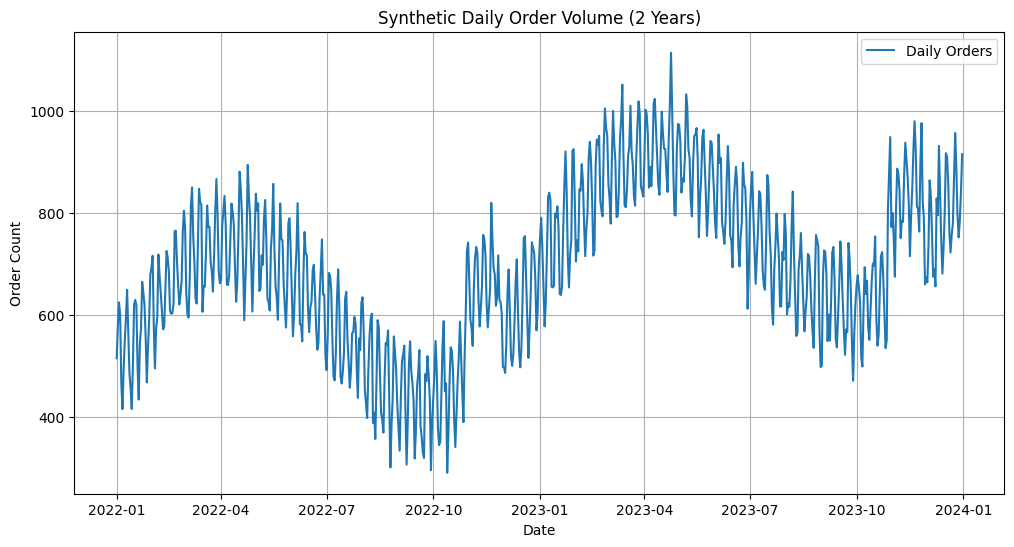

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Generate 2 years of daily data (730 days)
dates = pd.date_range(start='2022-01-01', periods=730, freq='D')
time_steps = np.arange(730)

# Base trend + Weekly seasonality + Yearly seasonality + Noise
trend = 0.5 * time_steps + 500
weekly_pattern = 100 * np.sin(2 * np.pi * time_steps / 7)
yearly_pattern = 200 * np.sin(2 * np.pi * time_steps / 365)
noise = np.random.normal(0, 30, size=730)

# Festival season boost (around autumn/winter, days 300-330 and 665-695)
festival_boost = np.zeros(730)
festival_boost[300:330] = 150
festival_boost[665:695] = 150

order_volume = trend + weekly_pattern + yearly_pattern + festival_boost + noise
df = pd.DataFrame({'Date': dates, 'Orders': order_volume})
df.set_index('Date', inplace=True)

plt.figure(figsize=(12, 6))
plt.plot(df['Orders'], label='Daily Orders')
plt.title('Synthetic Daily Order Volume (2 Years)')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.grid(True)
plt.show()

## Task 1: Sequence Preparation (30-day Look-back Window)

We scale our data using a MinMaxScaler and split it into training (80%) and test (20%) sets. Then we transform the sequences using a 30-day sliding window.

In [2]:
# Train-Test Split (80% Train, 20% Test)
train_size = int(len(df) * 0.8)
train_data = df.iloc[:train_size].values
test_data = df.iloc[train_size:].values

# Scale the data
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# Function to create sequences
def create_sequences(data, look_back=30):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0])
        y.append(data[i + look_back, 0])
    return np.array(X), np.array(y)

look_back = 30
X_train, y_train = create_sequences(train_scaled, look_back)
# For testing, we prepend the last look_back elements of train data to the test set
# so we can predict from the very first test day
full_test_data = np.concatenate((train_scaled[-look_back:], test_scaled), axis=0)
X_test, y_test = create_sequences(full_test_data, look_back)

# Reshape input to be [samples, time steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (554, 30, 1), y_train shape: (554,)
X_test shape: (146, 30, 1), y_test shape: (146,)


## Task 2 & 3: Train SimpleRNN and LSTM & Compare Loss and Training Time

We will define both architectures using 50 hidden units, train them for 40 epochs with a validation split of 10%, and profile their execution times.

In [3]:
epochs = 40
batch_size = 16
units = 50

# --- Train SimpleRNN ---
model_rnn = Sequential([
    SimpleRNN(units, input_shape=(look_back, 1)),
    Dense(1)
])
model_rnn.compile(optimizer='adam', loss='mean_squared_error')

print("Training SimpleRNN...")
start_time = time.time()
history_rnn = model_rnn.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.1, verbose=0)
rnn_train_time = time.time() - start_time
print(f"SimpleRNN trained in {rnn_train_time:.2f} seconds")

# --- Train LSTM ---
model_lstm = Sequential([
    LSTM(units, input_shape=(look_back, 1)),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mean_squared_error')

print("\nTraining LSTM...")
start_time = time.time()
history_lstm = model_lstm.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.1, verbose=0)
lstm_train_time = time.time() - start_time
print(f"LSTM trained in {lstm_train_time:.2f} seconds")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training SimpleRNN...
SimpleRNN trained in 14.65 seconds

Training LSTM...
LSTM trained in 21.56 seconds


### Training and Validation Loss Curves

Let's plot the comparative training and validation losses for both models.

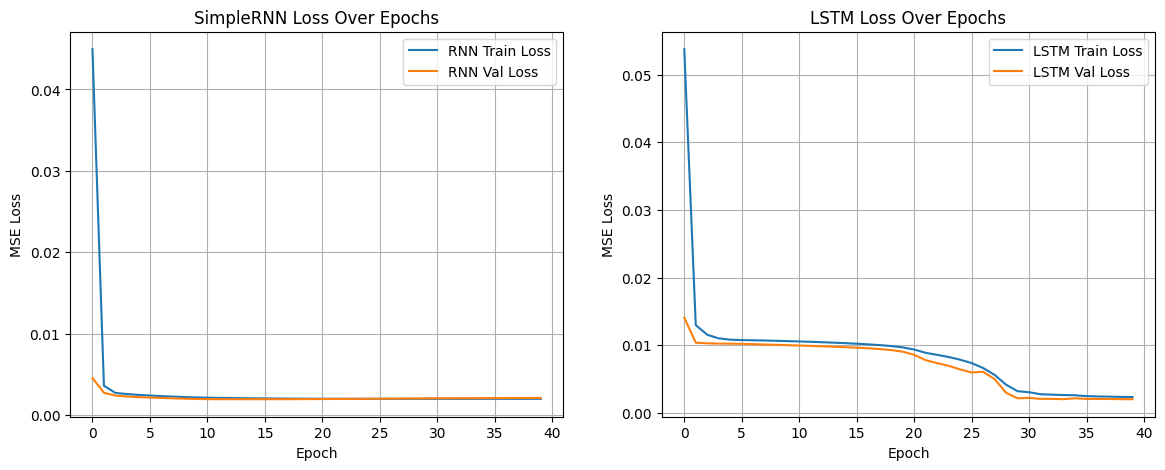

In [4]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_rnn.history['loss'], label='RNN Train Loss')
plt.plot(history_rnn.history['val_loss'], label='RNN Val Loss')
plt.title('SimpleRNN Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['loss'], label='LSTM Train Loss')
plt.plot(history_lstm.history['val_loss'], label='LSTM Val Loss')
plt.title('LSTM Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.show()

## Task 4 & 5: Compute Evaluation Metrics, Plot Forecasts, and Tabulate Results

We make predictions on the scaled test set, invert the predictions back to their original scale, calculate evaluation metrics (MAE, RMSE, MAPE), plot the forecasts, and output a summary comparison table.

In [5]:
# Predict
rnn_pred_scaled = model_rnn.predict(X_test)
lstm_pred_scaled = model_lstm.predict(X_test)

# Invert scaling
rnn_predictions = scaler.inverse_transform(rnn_pred_scaled)
lstm_predictions = scaler.inverse_transform(lstm_pred_scaled)
actual_values = scaler.inverse_transform(y_test.reshape(-1, 1))

# Metric Functions
def mape_score(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

rnn_mae = mean_absolute_error(actual_values, rnn_predictions)
rnn_rmse = np.sqrt(mean_squared_error(actual_values, rnn_predictions))
rnn_mape = mape_score(actual_values, rnn_predictions)

lstm_mae = mean_absolute_error(actual_values, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual_values, lstm_predictions))
lstm_mape = mape_score(actual_values, lstm_predictions)

# Tabulate Results
results_df = pd.DataFrame({
    'Metric': ['Training Time (s)', 'MAE', 'RMSE', 'MAPE (%)'],
    'SimpleRNN': [rnn_train_time, rnn_mae, rnn_rmse, rnn_mape],
    'LSTM': [lstm_train_time, lstm_mae, lstm_rmse, lstm_mape]
})

display(results_df)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step


,Metric,SimpleRNN,LSTM
0,Training Time (s),14.651812,21.559808
1,MAE,33.711365,35.146996
2,RMSE,45.939145,49.052359
3,MAPE (%),4.873738,4.971542


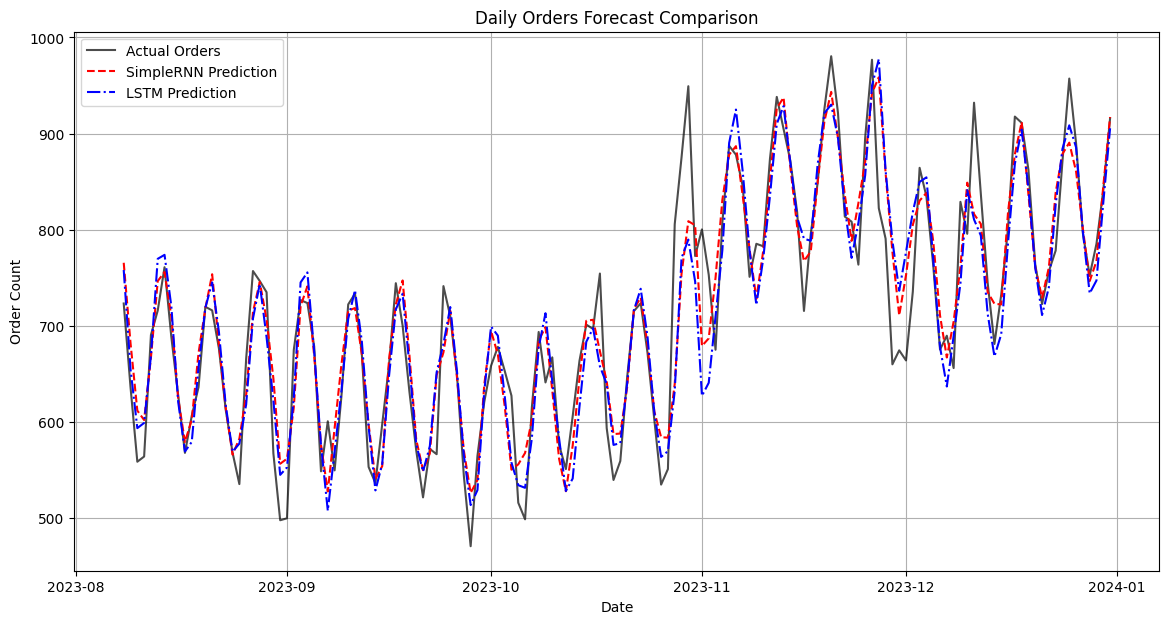

In [6]:
# Plot Forecasts
plt.figure(figsize=(14, 7))
plt.plot(df.index[train_size:], actual_values, label='Actual Orders', color='black', alpha=0.7)
plt.plot(df.index[train_size:], rnn_predictions, label='SimpleRNN Prediction', color='red', linestyle='--')
plt.plot(df.index[train_size:], lstm_predictions, label='LSTM Prediction', color='blue', linestyle='-.')
plt.title('Daily Orders Forecast Comparison')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.grid(True)
plt.show()